### Load libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load dataset Student Performance Dataset

In [8]:
student_data = pd.read_csv("../data/raw/student_data.csv")

### First look on data

In [9]:
student_data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Possible outlier: absences

The absences column shows a sharp gap between the 75th percentile and the maximum value:

25% — 0
50% (median) — 4
75% — 8
max — 75

Most students have 8 or fewer absences, but the maximum value (75) is nearly 10x higher than the 75th percentile. This suggests one or more students with an unusually high number of absences compared to the rest of the dataset. No action taken yet — will investigate further with a boxplot and decide how to handle it (keep, remove, or flag) during the data cleaning step.

In [10]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [11]:
student_data.shape

(395, 33)

In [12]:
student_data.select_dtypes(include='int64').columns

Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')

In [13]:
student_data.head(15)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


## Dataset Overview

### **Dataset Size**
The dataset contains **(395, 33)** entries.

---

## Column Summary

### **List of Columns**
## Column Descriptions

- **school** — student's school (GP or MS)
- **sex** — student's gender (M/F)
- **age** — student's age in years
- **address** — home address type (urban/rural)
- **famsize** — family size (≤3 or >3)
- **Pstatus** — parents' cohabitation status
- **Medu** — mother's education level
- **Fedu** — father's education level
- **Mjob** — mother's job
- **Fjob** — father's job
- **reason** — reason for choosing the school
- **guardian** — student's legal guardian
- **traveltime** — home-to-school travel time
- **studytime** — weekly study time
- **failures** — number of past class failures
- **schoolsup** — extra educational support
- **famsup** — family educational support
- **paid** — extra paid classes
- **activities** — extracurricular activities
- **nursery** — attended nursery school
- **higher** — wants higher education
- **internet** — internet access at home
- **romantic** — in a romantic relationship
- **famrel** — family relationship quality
- **freetime** — free time after school
- **goout** — going out with friends
- **Dalc** — workday alcohol consumption
- **Walc** — weekend alcohol consumption
- **health** — current health status
- **absences** — number of school absences
- **G1** — first period grade
- **G2** — second period grade
- **G3** — final grade


---

##  Data Types Overview

### **Columns by Data Type**

#### **Numeric Columns (16 total)**
- **age**
- **Medu**
- **Fedu**
- **traveltime**
- **studytime**
- **failures**
- **famrel**
- **freetime**
- **goout**
- **Dalc**
- **Walc**
- **health**
- **absences**
- **G1**
- **G2**
- **G3**

#### **Categorical Columns (17 total)**

- **school**
- **sex**
- **address**
- **famsize**
- **Pstatus**
- **Mjob**
- **Fjob**
- **reason**
- **guardian**
- **schoolsup**
- **famsup**
- **paid**
- **activities**
- **nursery**
- **higher**
- **internet**
- **romantic**

---

##  Additional Notes
- The dataset appears clean and well‑structured.
- No missing value analysis has been performed.
- No distribution analysis has been performed.
- Boxplot confirmed multiple outliers beyond ~20 absences, including one extreme case at 75 — this appears to be a genuine pattern (a subset of students with high absenteeism) rather than a single data entry error.
- The dataset contains a balanced mix of numeric and categorical features.


### Check nulls

In [14]:
student_data.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### Check duplicates

In [15]:
student_data.duplicated().sum()

np.int64(0)

### Make boxplot

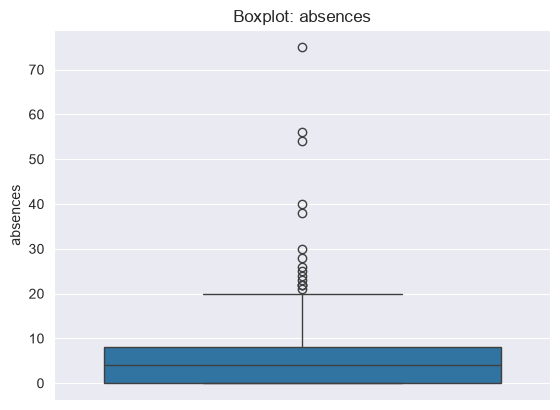

In [17]:
sns.boxplot(y=student_data['absences'])
plt.title('Boxplot: absences')
plt.show()

Boxplot confirms multiple outliers beyond ~20 absences, including one extreme case at 75 — this appears to be a genuine pattern (a subset of students with high absenteeism) rather than a single data entry error.

In [18]:
Q1 = student_data['absences'].quantile(0.25)
Q3 = student_data['absences'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}, upper_bound={upper_bound}")

Q1=0.0, Q3=8.0, IQR=8.0, upper_bound=20.0


### Make flag of absences

In [20]:
student_data['high_absences_flag'] = student_data['absences'] > upper_bound

### Count people with many absences and with not many absences

In [21]:
student_data['high_absences_flag'].value_counts()

high_absences_flag
False    380
True      15
Name: count, dtype: int64

Analysis of absences showed that a threshold of 20 (based on the Q3 + 1.5×IQR rule) separates 96% of students with a typical number of absences from 4% (15 students) with an anomalously high number.

Although this group is small, 15 students is not a single data error but a consistent subgroup. Therefore, it was decided not to remove these rows, but to create a binary feature, high_absences_flag.

This will allow further exploration during EDA of which factors (academic performance, health, family situation, etc.) are characteristic of this specific group, without distorting the overall distribution of absences by removing data.

In [22]:
student_data.isnull().sum().sum()

np.int64(0)

In [23]:
student_data.duplicated().sum()

np.int64(0)

In [27]:
student_data.to_csv('../data/processed/cleaned.csv', index=False)